# Live demo: a saved universal perturbation on SmolVLM-256M

The only notebook of the series that runs a model. It loads **SmolVLM-256M** (the model of notebooks 01–07) and the universal perturbation built for it by `real_vlm.py` (token attack, run to convergence, ξ = 10/255, 512 × 512). It then captions a few images that **were never used to build v**: clean, with v, and with random noise of the same size.

Runs on CPU in a few minutes (no GPU needed). It needs the Hugging Face cache of `HuggingFaceTB/SmolVLM-256M-Instruct` and `sentence-transformers/all-MiniLM-L6-v2`, plus a folder of images (default: the Imagenette validation set used in `python/`). Optional: the same with Qwen2-VL-2B and its end-to-end v (slower, set `RUN_QWEN = True`).

In [1]:
import os, sys, glob
sys.path.insert(0, os.path.abspath('minivlm'))
os.environ.setdefault('HF_HUB_OFFLINE', '1')         # use the local cache only
import numpy as np, torch
import matplotlib.pyplot as plt
from nb_utils import *
from real_vlm import RealVLM, load_square, load_any_v
from common import XI
use_style()

IMAGE_GLOB = '../python/data/imagenette2-320/val/*/*.JPEG'   # any folder of photos works
N_IMAGES = 6
DEVICE = 'cuda' if torch.cuda.is_available() and torch.cuda.get_device_properties(0).total_memory > 4e9 else 'cpu'
RUN_QWEN = False
torch.manual_seed(0)
files = sorted(glob.glob(IMAGE_GLOB))
files = files[::max(1, len(files) // N_IMAGES)][:N_IMAGES]   # spread over the classes
print(len(files), 'images, device', DEVICE)

6 images, device cpu


In [2]:
vlm = RealVLM('smolvlm-256m', DEVICE)
u8 = load_square(files, vlm.size)                               # 8-bit images, 512 x 512
v = load_any_v(RESULTS_DIR / 'smolvlm-256m' / 'uap_xi10.pt', vlm.size, XI, DEVICE)
noise = (torch.randint(0, 2, v.shape, device=DEVICE).float() * 2 - 1) * XI   # random ±ξ, same l_inf size
print('l_inf of v: %.1f/255, of the noise: %.1f/255' % (255 * v.abs().max(), 255 * noise.abs().max()))

l_inf of v: 10.0/255, of the noise: 10.0/255


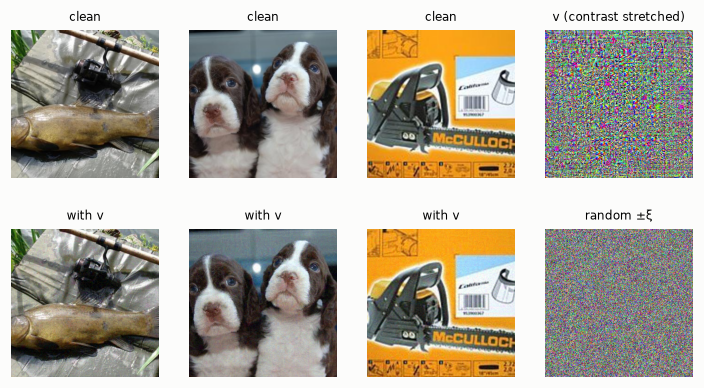

In [3]:
perturbed = torch.round(((u8.float() / 255 + v.cpu()).clamp(0, 1)) * 255).to(torch.uint8)
fig, axes = plt.subplots(2, 4, figsize=(8, 4.3))
for i in range(3):
    axes[0, i].imshow(u8[i].permute(1, 2, 0)); axes[0, i].set_title('clean', fontsize=8)
    axes[1, i].imshow(perturbed[i].permute(1, 2, 0)); axes[1, i].set_title('with v', fontsize=8)
axes[0, 3].imshow(v_image(v[0].cpu())); axes[0, 3].set_title('v (contrast stretched)', fontsize=8)
axes[1, 3].imshow(v_image(noise[0].cpu())); axes[1, 3].set_title('random ±ξ', fontsize=8)
for a in axes.flat:
    a.axis('off')
plt.show()

In [4]:
caps = {'clean': vlm.caption(u8, bs=3), 'universal v': vlm.caption(u8, v, bs=3), 'random ±ξ': vlm.caption(u8, noise, bs=3)}
sim_v, sim_n = caption_sim(caps['clean'], caps['universal v']), caption_sim(caps['clean'], caps['random ±ξ'])
rows = [[os.path.basename(os.path.dirname(f)), caps['clean'][i], '%s (%.2f)' % (caps['universal v'][i], sim_v[i]),
         '%s (%.2f)' % (caps['random ±ξ'][i], sim_n[i])] for i, f in enumerate(files)]
show_table(['image (class folder)', 'clean caption', 'with the universal v (similarity)', 'with random noise (similarity)'], rows)
print('changed (similarity < 0.5): universal v %d / %d, noise %d / %d' % ((sim_v < 0.5).sum(), len(files), (sim_n < 0.5).sum(), len(files)))

changed (similarity < 0.5): universal v 6 / 6, noise 0 / 6


| image (class folder) | clean caption | with the universal v (similarity) | with random noise (similarity) |
|---|---|---|---|
| n01440764 | In this image there is a fish, a fishing rod and a plant. | 12 people, 614, and 561; the company's founder and founder's logo; and the company's founder's name. (0.09) | In this image we can see a fish on the surface of the water. We can also see a fishing pole and some objects. (0.75) |
| n02102040 | In this image we can see two puppies. | obota:obby,O_ob old_ob_ob_ob_ob_ob_ob_ob_ob_ob_ob_ob_ob_ob_ob_ob (0.20) | In this image we can see two puppies. (1.00) |
| n03000684 | In this image, we can see a machine. | At 20020100000000000000000000000000000000 (0.15) | In this image we can see a vehicle. (0.59) |
| n03394916 | In this image we can see a man holding a musical instrument. | among children on families and child until extinct by children on dying on family and children by children on family by children's-onThe oldest-by oldest-byAton's, children's-by (-0.05) | In this image we can see a person holding a musical instrument. (0.93) |
| n03417042 | In this image we can see a truck on the road. | 20000001minio became extinct, and population, 20033, 8,1, 2, 1, 1, 2 (-0.00) | In this image we can see a truck, there are some objects and there is a sky. (0.79) |
| n03445777 | In this image we can see two persons standing on the ground and holding a golf ball. In the background there are trees. | This is a text document. (0.17) | In this image we can see a person standing on the ground and holding a golf club. In the background there are trees. (0.87) |

The perturbation is barely visible, the same for every image, and was built on other images; random noise of the same size leaves the captions essentially intact.

### Optional: Qwen2-VL-2B and the "mathematical equations" injection

Set `RUN_QWEN = True` above. Qwen2-VL-2B at 448 px with its end-to-end universal v (notebook 10, section 2). On CPU, expect about a minute per caption.

In [5]:
if RUN_QWEN:
    del vlm
    q = RealVLM('qwen2-vl-2b', DEVICE)
    uq = load_square(files[:3], q.size)
    vq = load_any_v(RESULTS_DIR / 'qwen2-vl-2b' / 'uap_cap_xi10.pt', q.size, XI, DEVICE)
    for a, b in zip(q.caption(uq, bs=1), q.caption(uq, vq, bs=1)):
        print('clean:', a, '\n  v  :', b, '\n')
else:
    print('skipped (RUN_QWEN = False)')

skipped (RUN_QWEN = False)


**To rebuild a perturbation** rather than load it (GPU, about an hour for SmolVLM-256M):

```
cd minivlm
python real_vlm.py --model smolvlm-256m                 # token attack, to convergence, then evaluation
python real_vlm.py --model smolvlm-256m --target caption --lr 1   # end-to-end attack
```